# What goes with a happy country? World Happiness 2021

An exploratory analysis of the **World Happiness Report 2021**: how 149 countries rate their lives, and how that rating relates to income, health, social support, freedom, generosity and corruption. Is it only money? And where does Egypt stand, and why?

**Data:** *World Happiness Report 2021* (Kaggle, from the report's data, based on the Gallup World Poll, 2018–2020). One row per country.

**Contents**
1. First look at the data
2. Questions
3. Cleaning
4. Feature engineering
5. Univariate analysis
6. Bivariate analysis
7. Multivariate analysis
8. Answers
9. Conclusion and limitations

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

import charts as ch      # the dashboard's charts: the same figures here and in the app

try:
    import kaleido  # noqa: F401  (static PNG copies: GitHub shows them, the README uses them)
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].width = 900
    HAS_PNG = True
except ImportError:
    pio.renderers.default = "plotly_mimetype+notebook"
    HAS_PNG = False

DATA, IMAGES = Path("../../data"), Path("images")
IMAGES.mkdir(exist_ok=True)


def titled(fig, text):
    # the app puts the title on the card; here it goes on the figure
    return fig.update_layout(title=text, margin_t=60)


def save(fig, name):
    if HAS_PNG:
        fig.write_image(IMAGES / name, width=1000, height=fig.layout.height or 450)

---
## 1. First look at the data

| Column | Meaning |
|---|---|
| `Country name`, `Regional indicator` | the country and one of 10 world regions |
| `Ladder score` | **the happiness score**: "Imagine a ladder from 0 (worst possible life) to 10 (best possible life). Where do you stand?" Average answer per country, 2018–2020, about 1,000 people per country per year |
| `Standard error of ladder score`, `upperwhisker`, `lowerwhisker` | the precision of that average and its 95% confidence interval |
| `Logged GDP per capita` | the natural **log** of GDP per person, in international dollars |
| `Social support` | share answering *yes* to "If you were in trouble, do you have relatives or friends you can count on?" (0–1) |
| `Healthy life expectancy` | years a newborn can expect to live in good health |
| `Freedom to make life choices` | share satisfied with their freedom to choose what to do with their life (0–1) |
| `Generosity` | share who donated to a charity last month, **after removing the effect of GDP**: positive = more generous than countries this rich |
| `Perceptions of corruption` | is corruption widespread in government? in business? (0–1, **higher = more corruption**) |
| `Ladder score in Dystopia` | the score of an imaginary country with the world's lowest value in all six factors: 2.43 in every row |
| `Explained by: …` (6 columns), `Dystopia + residual` | how many points of the score the report attributes to each factor, and the rest |

In [2]:
raw = pd.read_csv(DATA / "world_happiness_2021.csv")
print(raw.shape)
raw.info()

(149, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Country name                                149 non-null    object 
 1   Regional indicator                          149 non-null    object 
 2   Ladder score                                149 non-null    float64
 3   Standard error of ladder score              149 non-null    float64
 4   upperwhisker                                149 non-null    float64
 5   lowerwhisker                                149 non-null    float64
 6   Logged GDP per capita                       149 non-null    float64
 7   Social support                              149 non-null    float64
 8   Healthy life expectancy                     149 non-null    float64
 9   Freedom to make life choices                149 non-null    float64
 10  Gene

In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Ladder score,149.0,5.53,1.07,2.52,4.85,5.53,6.26,7.84
Standard error of ladder score,149.0,0.06,0.02,0.03,0.04,0.05,0.07,0.17
upperwhisker,149.0,5.65,1.05,2.60,4.99,5.62,6.34,7.90
lowerwhisker,149.0,5.42,1.09,2.45,4.71,5.41,6.13,7.78
Logged GDP per capita,149.0,9.43,1.16,6.64,8.54,9.57,10.42,11.65
Social support,149.0,0.81,0.11,0.46,0.75,0.83,0.90,0.98
Healthy life expectancy,149.0,64.99,6.76,48.48,59.80,66.60,69.60,76.95
Freedom to make life choices,149.0,0.79,0.11,0.38,0.72,0.80,0.88,0.97
Generosity,149.0,-0.02,0.15,-0.29,-0.13,-0.04,0.08,0.54
Perceptions of corruption,149.0,0.73,0.18,0.08,0.67,0.78,0.84,0.94


One row is a **country**, not a person: 149 rows, 20 columns, only two of them text. `Ladder score in Dystopia` never changes (min = max = 2.43), so it says nothing about the countries. `Generosity` goes down to −0.29, which is fine for a measure relative to GDP. There are no dates: one edition of the report allows comparisons between countries, not trends.

The report says the six `Explained by` columns plus `Dystopia + residual` add up to the score. A check:

In [4]:
parts_cols = raw.columns[raw.columns.str.startswith("Explained by")].tolist() + ["Dystopia + residual"]
(raw[parts_cols].sum(axis=1) - raw["Ladder score"]).abs().max()

0.002000000000000224

The largest gap is 0.002, just rounding. These 7 columns are not new measurements: they cut each score into pieces, repeating the six factors in another form.

---
## 2. Questions

| # | Question | Columns |
|---|---|---|
| Q1 | How is happiness spread across the world? | `Ladder score` |
| Q2 | Which regions are the happiest, and which the least? | score by `Regional indicator` |
| Q3 | Which factors move together with happiness? | the six factors |
| Q4 | Is money everything? Are there countries much happier, or sadder, than others with the same GDP? | `Logged GDP per capita`, score |
| Q5 | Does social support still matter between countries of the same income? | `Social support`, GDP, score |
| Q6 | Where is Egypt, and what pulls its score down? | ranks, the report's split |
| Q7 | Do the world's patterns hold inside the Middle East and North Africa? | factors by region |

---
## 3. Cleaning

### 3.1 Scope
- **Kept:** the country, the region, the score and the six factors; every question needs them.
- **Dropped:** the standard error and the whiskers (they describe the precision of each score, not differences between countries) and Dystopia (constant).
- **Kept apart:** the report's split, needed only for Q6, in its own table `explained`.

The clean table is built by `ch.to_clean()` (also used by the dashboard): renamed columns plus three new ones described in Section 4.

In [5]:
df = ch.to_clean(raw)

explained = raw[["Country name"] + parts_cols].copy()
explained.columns = ["country", "gdp", "social_support", "life_expectancy", "freedom", "generosity",
                     "corruption", "dystopia_residual"]
df.head()

,country,region,happiness,log_gdp,social_support,life_expectancy,freedom,generosity,corruption,rank,gdp_usd,income_group
0,Finland,Western Europe,7.842,10.775,0.954,72.0,0.949,-0.098,0.186,1,47810.0,High
1,Denmark,Western Europe,7.620,10.933,0.954,72.7,0.946,0.030,0.179,2,55990.0,High
2,Switzerland,Western Europe,7.571,11.117,0.942,74.4,0.919,0.025,0.292,3,67310.0,High
3,Iceland,Western Europe,7.554,10.878,0.983,73.0,0.955,0.160,0.673,4,53000.0,High
4,Netherlands,Western Europe,7.464,10.932,0.942,72.4,0.913,0.175,0.338,5,55940.0,High


### 3.2 Missing values, duplicates and validation rules
A file without empty cells can still hold impossible values, so the rules are written as `assert` statements that stop the notebook if one fails.

In [6]:
print("missing:", df.isna().sum().sum(), "| duplicate rows:", df.duplicated().sum(),
      "| repeated countries:", df["country"].duplicated().sum(),
      "| names with extra spaces:", (df["country"] != df["country"].str.strip()).sum())

assert df["happiness"].between(0, 10).all()
assert df[["social_support", "freedom", "corruption"]].apply(lambda s: s.between(0, 1)).all().all()
assert df["life_expectancy"].between(30, 90).all()
assert df["country"].is_unique
print("all rules pass")

missing: 0 | duplicate rows: 0 | repeated countries: 0 | names with extra spaces: 0
all rules pass


### 3.3 Negative generosity

In [7]:
(df["generosity"] < 0).sum()

np.int64(86)

86 of 149 countries have a negative generosity. Dropping them would remove more than half of the world, and it would be wrong: generosity is measured relative to GDP, so negative means "gives less than other countries this rich". It is the definition of the column, not an error.

### 3.4 Unusual observations

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

num_cols = ["happiness"] + ch.FACTORS
df[num_cols].apply(iqr_outliers).sum()

happiness           1
log_gdp             0
social_support      3
life_expectancy     0
freedom             1
generosity          4
corruption         11
dtype: int64

In [9]:
c = df["corruption"]
q1, q3 = c.quantile([0.25, 0.75])
print("normal range:", round(q1 - 1.5 * (q3 - q1), 2), "to", round(q3 + 1.5 * (q3 - q1), 2), "| median:", round(c.median(), 2))
df.loc[iqr_outliers(c), ["country", "region", "corruption", "rank"]].sort_values("corruption")

normal range: 0.4 to 1.11 | median: 0.78


,country,region,corruption,rank
31,Singapore,Southeast Asia,0.082,32
146,Rwanda,Sub-Saharan Africa,0.167,147
1,Denmark,Western Europe,0.179,2
0,Finland,Western Europe,0.186,1
6,Sweden,Western Europe,0.237,7
8,New Zealand,North America and ANZ,0.242,9
5,Norway,Western Europe,0.270,6
2,Switzerland,Western Europe,0.292,3
4,Netherlands,Western Europe,0.338,5
14,Ireland,Western Europe,0.363,15


All 11 corruption outliers have **too little** corruption (higher = more). Most of the world sits high (median 0.78) and the scale stops at 1, so the only way to stand out is to be very clean. Nine are rich Western countries in the top 15 for happiness, plus Singapore (0.08) and, surprisingly, Rwanda (0.17), 147th of 149 in happiness: low corruption alone does not make a country happy.

In [10]:
odd = (iqr_outliers(df["happiness"]) | iqr_outliers(df["social_support"]) | iqr_outliers(df["freedom"])
       | iqr_outliers(df["generosity"]))
df.loc[odd, ["country", "happiness", "social_support", "freedom", "generosity"]]

,country,happiness,social_support,freedom,generosity
81,Indonesia,5.345,0.811,0.873,0.542
97,Gambia,5.051,0.690,0.697,0.424
98,Benin,5.045,0.489,0.757,-0.034
125,Myanmar,4.426,0.779,0.876,0.509
139,Burundi,3.775,0.490,0.626,-0.024
142,Haiti,3.615,0.540,0.593,0.422
148,Afghanistan,2.523,0.463,0.382,-0.102


The other outliers are real too: Afghanistan's 2.5 is a very hard life, not a typo; Benin and Burundi have very low support; Indonesia, Gambia, Myanmar and Haiti are very generous for their income. All are kept.

**Cleaning log**

| Finding | Decision | Why |
|---|---|---|
| uncertainty and Dystopia columns | dropped | they don't compare countries |
| the report's split | kept apart in `explained` | repeats the factors; needed only for Q6 |
| no missing values, duplicates or extra spaces | nothing to do | checked, not assumed |
| negative generosity | kept | relative to GDP by definition |
| IQR outliers | kept | real countries, not errors |

---
## 4. Feature engineering

`to_clean()` added three columns:
- `rank`: 1 for the happiest country;
- `gdp_usd`: GDP per person in dollars, `exp(log_gdp)` rounded to 10;
- `income_group`: `log_gdp` cut into three groups of equal size, Low, Middle and High.

In [11]:
egypt = df.loc[df["country"] == "Egypt"].iloc[0]
print("Egypt: rank", egypt["rank"], "| income group:", egypt["income_group"], "| GDP per person:", egypt["gdp_usd"])
df.groupby("income_group", observed=True)["gdp_usd"].agg(["count", "min", "max"])

Egypt: rank 132 | income group: Middle | GDP per person: 11700.0


,count,min,max
income_group,,,
Low,50,760.0,8540.0
Middle,49,8550.0,23650.0
High,50,25720.0,114350.0


At about 11,700 dollars per person, Egypt is in the **Middle** group (8,550–23,650 dollars), yet it ranks 132nd of 149 in happiness: a first hint that money alone cannot explain the rank.

The clean table is saved for the dashboard:

In [12]:
df.to_csv(DATA / "world_happiness_clean.csv", index=False)
pd.read_csv(DATA / "world_happiness_clean.csv").shape

(149, 12)

---
## 5. Univariate analysis

### 5.1 Happiness (Q1)

mean      5.53
median    5.53
std       1.07
q1        4.85
q3        6.26
skew     -0.10
dtype: float64


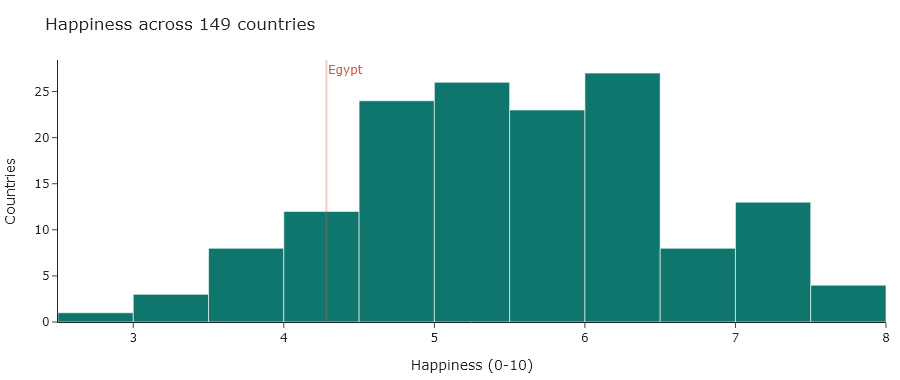

In [13]:
h = df["happiness"]
print(pd.Series({"mean": h.mean(), "median": h.median(), "std": h.std(), "q1": h.quantile(0.25),
                 "q3": h.quantile(0.75), "skew": h.skew()}).round(2))
fig = titled(ch.happiness_hist(df), "Happiness across 149 countries")
save(fig, "happiness_hist.png")
fig

Nicely symmetric: mean and median are both 5.53 (skew −0.10). The middle half of the world sits between 4.85 and 6.26. Egypt, at 4.28, is below Q1: the bottom quarter.

### 5.2 GDP: dollars or log?

skew in USD: 1.5 | in log: -0.35 | mean: 21560 | median: 14310.0


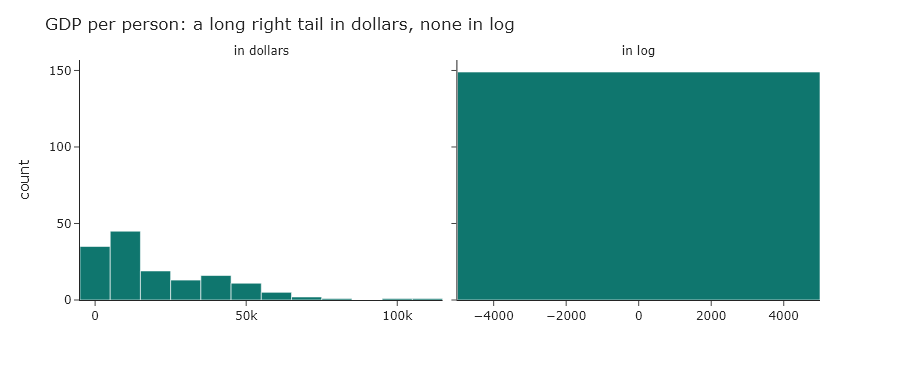

In [14]:
print("skew in USD:", round(df["gdp_usd"].skew(), 2), "| in log:", round(df["log_gdp"].skew(), 2),
      "| mean:", round(df["gdp_usd"].mean()), "| median:", df["gdp_usd"].median())
long = df.melt(value_vars=["gdp_usd", "log_gdp"], var_name="scale")
fig = px.histogram(long, x="value", facet_col="scale", nbins=15)
fig.update_xaxes(matches=None, title=None)
fig.for_each_annotation(lambda a: a.update(text={"scale=gdp_usd": "in dollars", "scale=log_gdp": "in log"}[a.text]))
titled(fig, "GDP per person: a long right tail in dollars, none in log")

In dollars, a few very rich countries stretch the axis (skew 1.50, and the mean of 21,560 is far above the median of 14,310); in log, the skew drops to −0.35. There is a human reason too: an extra 1,000 dollars changes a lot at 2,000 a year and almost nothing at 80,000. The log measures change relative to what a country has, so doubling income is the same step everywhere.

### 5.3 The other factors

In [15]:
df[num_cols].skew().round(2).sort_values()

corruption        -1.58
social_support    -0.94
freedom           -0.75
life_expectancy   -0.52
log_gdp           -0.35
happiness         -0.10
generosity         1.01
dtype: float64

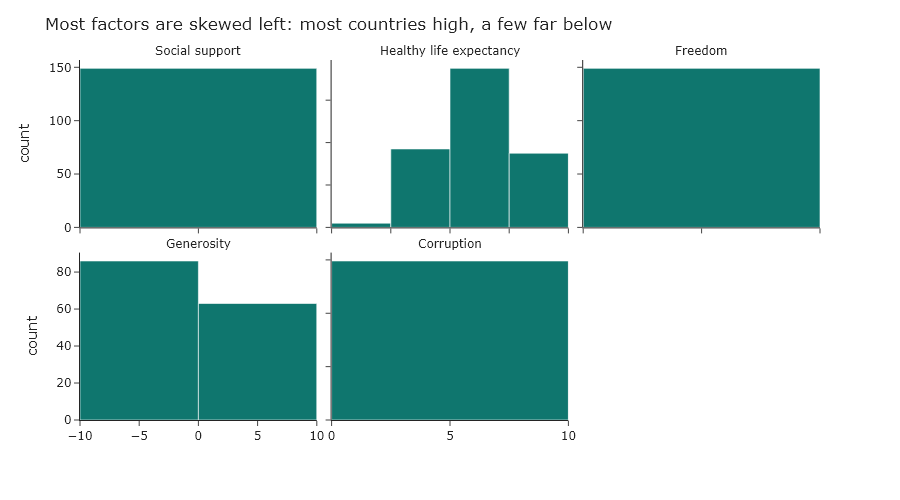

In [16]:
long = df.melt(value_vars=["social_support", "life_expectancy", "freedom", "generosity", "corruption"],
               var_name="factor")
fig = px.histogram(long, x="value", facet_col="factor", facet_col_wrap=3, nbins=15, height=500)
fig.update_xaxes(matches=None, title=None).update_yaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=ch.LABELS[a.text.split("=")[-1]]))
titled(fig, "Most factors are skewed left: most countries high, a few far below")

Every factor except generosity is skewed left: most countries are high and a few are far below. Corruption is the strongest (−1.58): almost everywhere, people see a lot of corruption, and only a handful of countries are clean. Generosity leans right (1.01), pulled by its very generous outliers.

### 5.4 Regions

In [17]:
df["region"].value_counts()

region
Sub-Saharan Africa                    36
Western Europe                        21
Latin America and Caribbean           20
Central and Eastern Europe            17
Middle East and North Africa          17
Commonwealth of Independent States    12
Southeast Asia                         9
South Asia                             7
East Asia                              6
North America and ANZ                  4
Name: count, dtype: int64

The regions differ a lot in size: 36 countries in Sub-Saharan Africa, only 4 in North America & ANZ. An average of 4 countries can move a lot with a single one, so region averages need care.

---
## 6. Bivariate analysis

### 6.1 Happiness by region (Q2)

In [18]:
(df.groupby("region")["happiness"].agg(["count", "mean", "median", "min", "max"])
   .round(2).sort_values("median", ascending=False))

,count,mean,median,min,max
region,,,,,
North America and ANZ,4,7.13,7.14,6.95,7.28
Western Europe,21,6.91,7.08,5.54,7.84
Central and Eastern Europe,17,5.98,6.08,5.10,6.96
Latin America and Caribbean,20,5.91,5.99,3.62,7.07
East Asia,6,5.81,5.76,5.34,6.58
Commonwealth of Independent States,12,5.47,5.47,4.88,6.18
Southeast Asia,9,5.41,5.38,4.43,6.38
South Asia,7,4.44,4.93,2.52,5.27
Middle East and North Africa,17,5.22,4.89,3.66,7.16


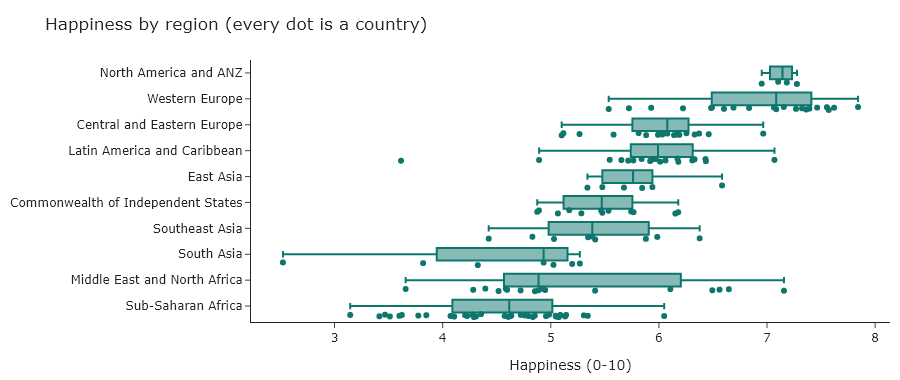

In [19]:
fig = titled(ch.group_spread(df, "region"), "Happiness by region (every dot is a country)")
save(fig, "regions.png")
fig

North America & ANZ (median 7.14) and Western Europe (7.08) are on top, Sub-Saharan Africa (4.62) at the bottom. The Middle East and North Africa has the widest range (3.66 to 7.16): mean 5.22 but median 4.89. A few rich, happy countries (the Gulf, Israel) pull the mean up while most of the region, Egypt included, sits low; the median tells the honest story.

### 6.2 Which factors move with happiness? (Q3)

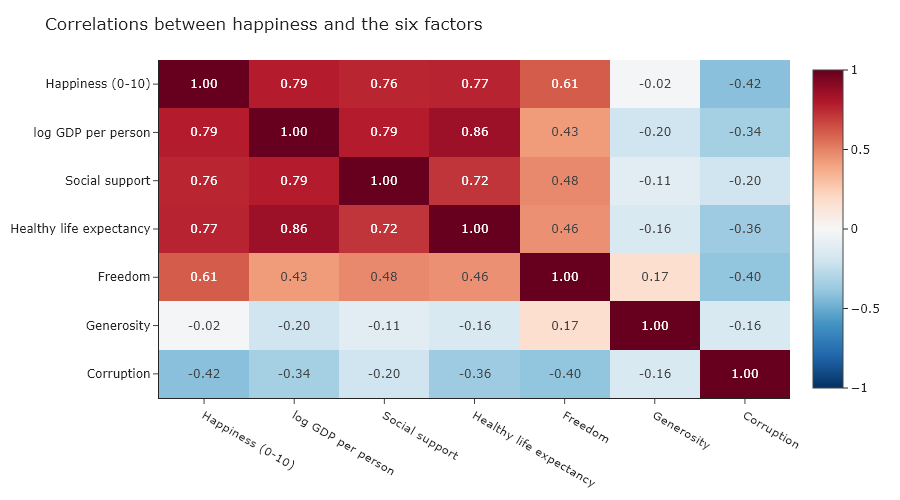

In [20]:
titled(ch.corr_heatmap(df), "Correlations between happiness and the six factors")

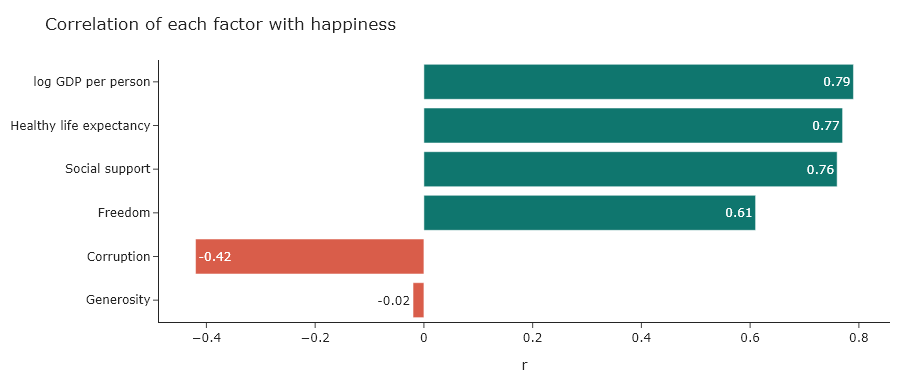

In [21]:
titled(ch.corr_bars(df), "Correlation of each factor with happiness")

GDP (0.79), life expectancy (0.77) and social support (0.76) move most with happiness, then freedom (0.61). Corruption goes the other way (−0.42), and generosity shows no link (−0.02).

### 6.3 GDP and happiness (Q4)

r = 0.79


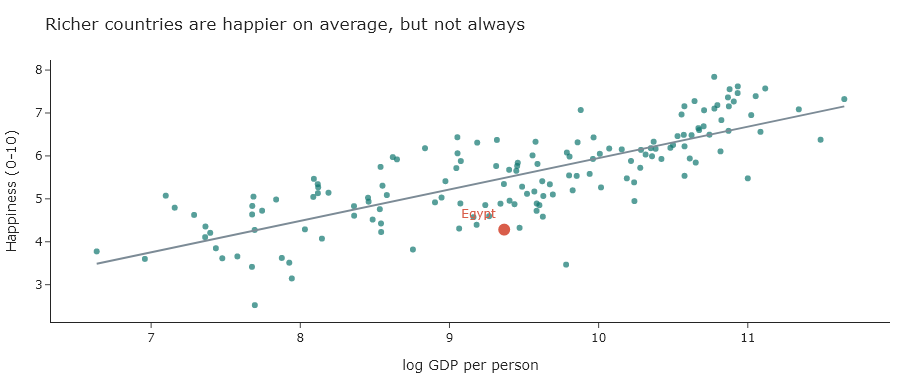

In [22]:
print("r =", round(df["log_gdp"].corr(df["happiness"]), 2))
fig = titled(ch.factor_scatter(df, "log_gdp"), "Richer countries are happier on average, but not always")
save(fig, "gdp_happiness.png")
fig

A clear upward cloud (r = 0.79), but at any GDP level there are countries 2 points or more apart, so money is not the whole story. Egypt sits well below the line: less happy than countries with the same GDP.

### 6.4 Generosity and happiness (Q3)

r = -0.02


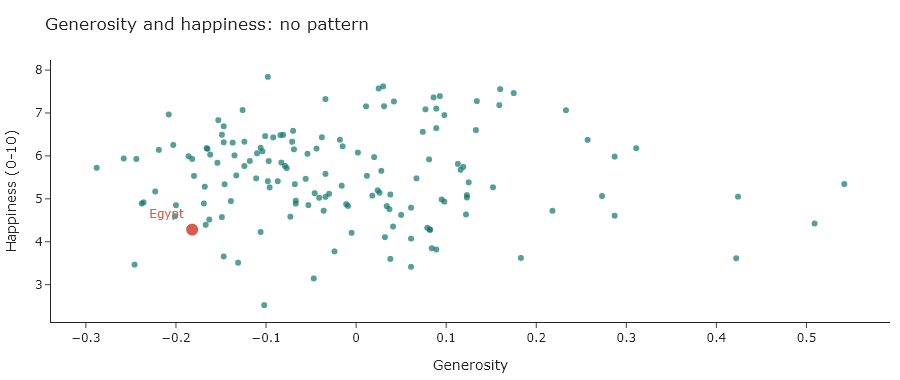

In [23]:
print("r =", round(df["generosity"].corr(df["happiness"]), 2))
titled(ch.factor_scatter(df, "generosity", trend=False), "Generosity and happiness: no pattern")

A shapeless cloud (r = −0.02): countries that give more for their income are not happier on average. This is about **countries**; a rule about country averages says nothing about one person.

### 6.5 Correlation is not causation
GDP has the highest correlation with happiness, but it also moves with life expectancy (0.86) and social support (0.79): rich countries also have better hospitals and stronger safety nets. This table cannot tell which one does the work, or whether something else, a stable government for example, drives all of them.

---
## 7. Multivariate analysis

### 7.1 Social support inside each income group (Q5)

In [24]:
(df.groupby("income_group", observed=True)[["happiness", "social_support"]]
   .apply(lambda g: g["happiness"].corr(g["social_support"])).round(2))

income_group
Low       0.54
Middle    0.48
High      0.67
dtype: float64

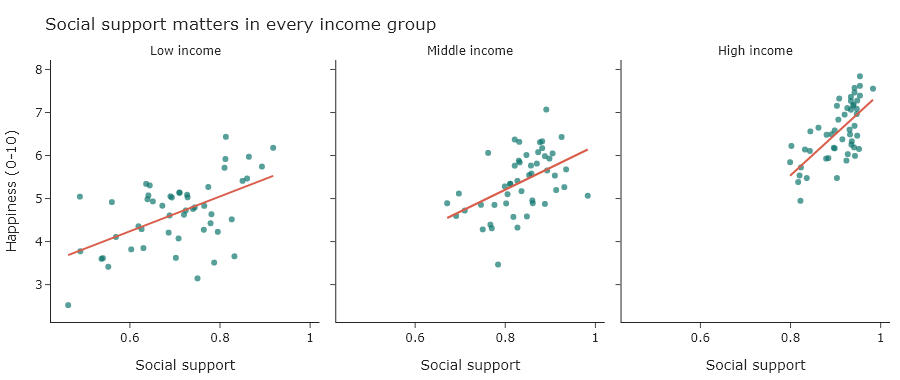

In [25]:
fig = titled(ch.support_by_income(df), "Social support matters in every income group")
save(fig, "support_by_income.png")
fig

Social support is not just GDP in disguise: inside every income group its correlation with happiness stays positive, 0.54 (Low), 0.48 (Middle) and 0.67 (High). Among countries with the same money, those where people have someone to call are happier.

### 7.2 What is Egypt's score made of? (Q6)

dystopia_residual    38.0
gdp                  22.0
social_support       15.0
life_expectancy      10.0
freedom              10.0
generosity            2.0
corruption            2.0
Name: Egypt, dtype: float64


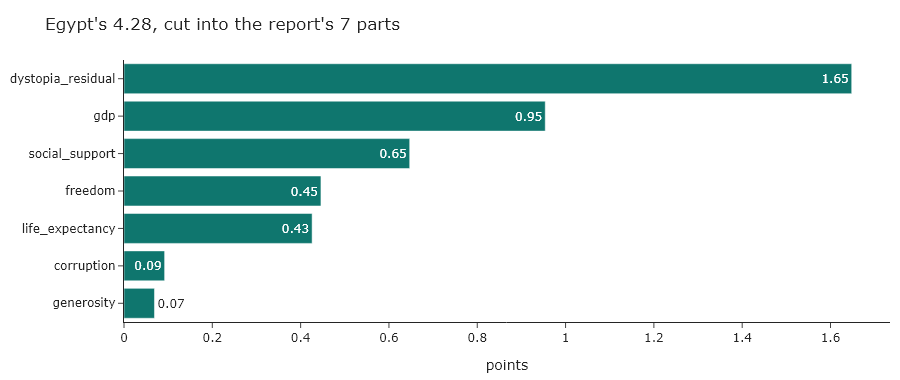

In [26]:
parts = explained.set_index("country")
egypt_parts = parts.loc["Egypt"]
print((egypt_parts / egypt_parts.sum() * 100).round(0).sort_values(ascending=False))
titled(ch.parts_bars(egypt_parts), "Egypt's 4.28, cut into the report's 7 parts")

The longest bar, `dystopia_residual` (1.65 points), is not the residual: 2.43 of it is Dystopia, the same for every country. Egypt's real residual is 1.65 − 2.43 = **−0.78**: the six factors (2.63 points) plus Dystopia predict 5.06, and Egypt scores 4.28. Egyptians are less happy than their numbers predict. Among the six factors, GDP brings the most (0.95 points), then social support (0.65); corruption and generosity bring almost nothing.

### 7.3 Egypt against Finland

In [27]:
gap = (parts.loc["Finland"] - parts.loc["Egypt"]).round(2)
print(gap.sort_values(ascending=False))

ranks = df[num_cols].rank(ascending=False, method="min")
ranks["corruption"] = df["corruption"].rank(method="min")          # lower corruption is better
ranks.loc[df["country"] == "Egypt"].iloc[0].astype(int)

dystopia_residual    1.61
gdp                  0.49
social_support       0.46
corruption           0.39
life_expectancy      0.32
freedom              0.24
generosity           0.05
dtype: float64


happiness          132
log_gdp             86
social_support     111
life_expectancy    106
freedom            101
generosity         134
corruption          79
Name: 131, dtype: int64

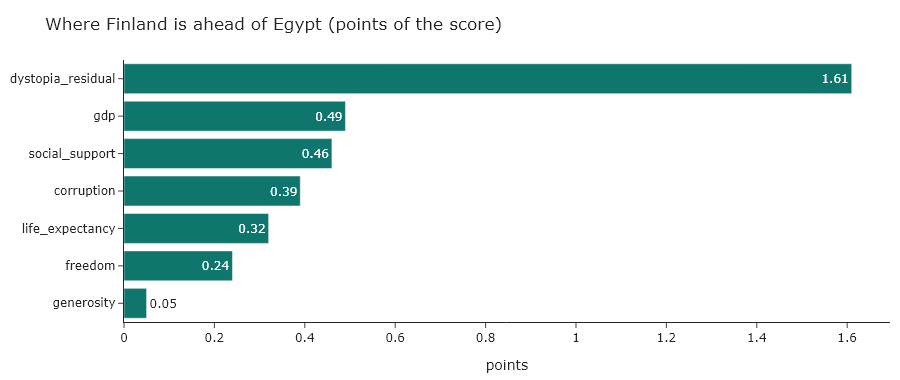

In [28]:
titled(ch.parts_bars(gap), "Where Finland is ahead of Egypt (points of the score)")

Finland is 3.56 points ahead. The biggest piece is the residual (1.61): Dystopia cancels in the subtraction, leaving Finland's +0.82 against Egypt's −0.78. Then GDP (0.49), social support (0.46) and corruption (0.39). The world ranks tell the same story: Egypt is 86th in GDP but 111th in social support, 106th in life expectancy, 101st in freedom and 134th in generosity. Its income is mid-table; everything else is lower.

### 7.4 Does the world pattern hold in the Middle East and North Africa? (Q7)

In [29]:
mena = df[df["region"] == "Middle East and North Africa"]
pd.DataFrame({"world": df[ch.FACTORS].corrwith(df["happiness"]),
              "mena": mena[ch.FACTORS].corrwith(mena["happiness"])}).round(2)

,world,mena
log_gdp,0.79,0.87
social_support,0.76,0.53
life_expectancy,0.77,0.69
freedom,0.61,0.72
generosity,-0.02,0.44
corruption,-0.42,-0.56


Freedom (0.72 against 0.61) and GDP (0.87 against 0.79) are stronger in the region, because the rich Gulf countries are also the happiest. Social support is weaker (0.53 against 0.76), and generosity jumps from −0.02 to 0.44. With only 17 countries, one or two of them can swing these correlations a lot.

---
## 8. Answers

| # | Answer |
|---|---|
| Q1 | Symmetric around 5.5 (mean = median = 5.53); the middle half is between 4.85 and 6.26; from Afghanistan (2.52) to Finland (7.84). |
| Q2 | North America & ANZ (median 7.14) and Western Europe (7.08) on top, Sub-Saharan Africa (4.62) at the bottom; the Middle East and North Africa's median (4.89) is far below its mean (5.22). |
| Q3 | GDP (0.79), life expectancy (0.77) and social support (0.76) move most with happiness; freedom 0.61; corruption −0.42; generosity −0.02. |
| Q4 | No: GDP sets the level (r = 0.79), but countries with the same GDP can be 2 points apart, and Egypt sits well below the line. |
| Q5 | Yes: inside each income group the correlation with happiness stays at 0.48–0.67. |
| Q6 | 132nd of 149; residual −0.78 (the factors predict 5.06, it scores 4.28); behind Finland mostly in the residual, GDP, social support and corruption; 86th in GDP but 101st–134th in support, health, freedom and generosity. |
| Q7 | Mostly yes, with GDP and freedom even stronger in the region, but on only 17 countries. |

---
## 9. Conclusion and limitations

**Findings**
1. Happiness follows money, health and social support, and the three are tied together.
2. Social support matters even between countries of the same income.
3. Egypt is less happy than countries of the same income: 86th in GDP, lower in support, health and freedom, and a negative residual.

**Limitations**
- One edition, averaged over 2018–2020: no trends, and the pandemic year weighs in.
- Countries, not people: country averages don't transfer to individuals.
- Correlation only: nothing here proves a cause.
- A survey answer depends on culture and on how people read the question.
- Small groups: some regions have only 4–7 countries.

**Next steps**
- How Egypt's score changed over the years, from the report's yearly panel data.
- What is inside the large residual, with other data such as unemployment or inflation.

The cleaned table (`data/world_happiness_clean.csv`) feeds the interactive dashboard in this folder.